In [1]:
import pandas as pd
import numpy as np
from statistics import mean
import os
import sys

# Ruta absoluta al directorio src
src_path = os.path.abspath("../src")
sys.path.append(src_path)

# Ahora puedes importar el módulo utils
from utils.exploration_utils import preprocess_data, evaluar_escenarios_trading, calcular_features_vela
from utils.exploration_utils import feature_engineering_rsi, sma_engineering_from_close, analizar_metricas_por_umbral


pd.set_option('display.max_columns', None)


In [2]:
def read_csv_files(folder_path):
    # List all CSV files in the folder
    all_files = os.listdir(folder_path)
    csv_files = [os.path.join(folder_path, file) for file in all_files if file.endswith('.csv')]
    
    # Read and concatenate all CSV files into a single DataFrame
    combined_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
    
    return combined_df

In [3]:
# Read Data:
folder_path = '../data/EURUSD/5mins'
df_EURUSD_5min = read_csv_files(folder_path)
df_EURUSD_5min = preprocess_data(df_EURUSD_5min)

In [4]:
df_EURUSD_5min_10000 = df_EURUSD_5min.head(10000)

In [9]:
df_EURUSD_5min_10000.head(1)

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute
0,20100103 17:15:00 US/Eastern,1.43085,1.4309,1.4308,1.4309,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15


In [72]:
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

def calculate_mass(touch_count, revalidation_count, bonus_factor, duration, K_age, last_touch_age, T_recency, reaction_magnitude, prominence_mean, gamma=5, delta=0.01, epsilon=0.001):
    """
    Calcula la masa del cluster con la siguiente fórmula:
    
    mass = [touch_count * (1 + revalidation_count * bonus_factor)]^gamma *
           exp(-duration / K_age) *
           exp(-last_touch_age / T_recency) *
           (reaction_magnitude + delta) *
           (prominence_mean + epsilon)
    """
    base = touch_count * (1 + revalidation_count * bonus_factor)
    recency_factor = np.exp(-last_touch_age / T_recency)
    mass = (base ** gamma) * np.exp(-duration / K_age) * recency_factor * (reaction_magnitude + delta) * (prominence_mean + epsilon)
    return mass

def detect_peaks_in_close(df, prominence=0.0001, distance=5):
    """Detecta picos en la columna 'close'."""
    close_array = df['close'].values
    peak_indices, properties = find_peaks(close_array, prominence=prominence, distance=distance)
    prominences = properties["prominences"]
    return [(int(idx), close_array[idx], float(prom)) for idx, prom in zip(peak_indices, prominences)]

def cluster_peaks_dynamic_center(peaks, df, pips_range=0.001, reaction_window=50, current_index=None, level_type='R', K_age=100, T_recency=50, bonus_factor=0.1):
    """
    Agrupa los picos en clusters con centro dinámico.
    Calcula `last_touch_age`, `reaction_magnitude` y `mass` dentro del mismo proceso.
    """
    if not peaks:
        return []
    
    revalidation_threshold = 50  # Número de velas para considerar revalidación
    
    peaks_sorted = sorted(peaks, key=lambda x: x[1])  # Ordenar por precio
    clusters = []
    current_cluster = [peaks_sorted[0]]
    cluster_center = peaks_sorted[0][1]
    last_peak_index = peaks_sorted[0][0]
    revalidation_count = 0
    
    for i in range(1, len(peaks_sorted)):
        idx, price, prom = peaks_sorted[i]
        dist = abs(price - cluster_center)
        
        if dist <= pips_range:
            if idx - last_peak_index > revalidation_threshold:
                revalidation_count += 1
            current_cluster.append((idx, price, prom))
            cluster_center = np.mean([p[1] for p in current_cluster])
            last_peak_index = idx
        else:
            indices = [p[0] for p in current_cluster]
            prices = [p[1] for p in current_cluster]
            prominences = [p[2] for p in current_cluster]
            touch_count = len(current_cluster)
            prominence_mean = np.mean(prominences)
            duration = max(indices) - min(indices)
            max_idx = max(indices)
            
            # Calcular last_touch_age dentro del mismo loop
            last_touch_age = current_index - max_idx if current_index else 0
            
            # Calcular reaction_magnitude dentro del mismo loop
            start = max_idx + 1
            end = min(start + reaction_window, len(df))
            if start >= len(df):
                reaction_magnitude = 0
            else:
                window_prices = df.iloc[start:end]['close'].values
                if level_type == 'R':
                    reaction_magnitude = cluster_center - np.min(window_prices)
                else:
                    reaction_magnitude = np.max(window_prices) - cluster_center
                reaction_magnitude = max(reaction_magnitude, 0)  # Evitar valores negativos
            
            # Calcular la masa dentro del mismo loop
            mass = calculate_mass(touch_count, revalidation_count, bonus_factor, duration, K_age, last_touch_age, T_recency, reaction_magnitude, prominence_mean)
            
            clusters.append({
                'cluster_center': float(np.mean(prices)),
                'touch_count': touch_count,
                'revalidation_count': revalidation_count,
                'duration': duration,
                'prominence_mean': prominence_mean,
                'reaction_magnitude': reaction_magnitude,
                'last_touch_age': last_touch_age,
                'mass': mass,  # Se guarda directamente
                'min_idx': min(indices),
                'max_idx': max_idx
            })
            
            current_cluster = [(idx, price, prom)]
            cluster_center = price
            last_peak_index = idx
            revalidation_count = 0
    
    if current_cluster:
        indices = [p[0] for p in current_cluster]
        prices = [p[1] for p in current_cluster]
        prominences = [p[2] for p in current_cluster]
        touch_count = len(current_cluster)
        prominence_mean = np.mean(prominences)
        duration = max(indices) - min(indices)
        max_idx = max(indices)
        last_touch_age = current_index - max_idx if current_index else 0

        start = max_idx + 1
        end = min(start + reaction_window, len(df))
        if start >= len(df):
            reaction_magnitude = 0
        else:
            window_prices = df.iloc[start:end]['close'].values
            if level_type == 'R':
                reaction_magnitude = cluster_center - np.min(window_prices)
            else:
                reaction_magnitude = np.max(window_prices) - cluster_center
            reaction_magnitude = max(reaction_magnitude, 0)

        mass = calculate_mass(touch_count, revalidation_count, bonus_factor, duration, K_age, last_touch_age, T_recency, reaction_magnitude, prominence_mean)

        clusters.append({
            'cluster_center': float(np.mean(prices)),
            'touch_count': touch_count,
            'revalidation_count': revalidation_count,
            'duration': duration,
            'prominence_mean': prominence_mean,
            'reaction_magnitude': reaction_magnitude,
            'last_touch_age': last_touch_age,
            'mass': mass,
            'min_idx': min(indices),
            'max_idx': max_idx
        })
    
    clusters.sort(key=lambda c: c['cluster_center'])
    return clusters

def find_peaks_and_cluster_dynamic_center(
    df,
    max_rows=10000,
    prominence=0.0001,
    distance=5,
    pips_range=0.001,
    reaction_window=50,
    level_type='R',
    K_age=100,
    T_recency=50,
    bonus_factor=0.1
):
    """
    Procesa las primeras max_rows de df, calculando last_touch_age, reaction_magnitude y mass directamente.
    """
    df_chunk = df.copy()
    peaks_list = detect_peaks_in_close(df_chunk, prominence=prominence, distance=distance)
    
    current_index = max_rows - 1
    clusters = cluster_peaks_dynamic_center(peaks_list, df_chunk, pips_range=pips_range, reaction_window=reaction_window, current_index=current_index, level_type=level_type, K_age=K_age, T_recency=T_recency, bonus_factor=bonus_factor)
    
    df_peaks = pd.DataFrame(peaks_list, columns=['idx', 'price', 'prominence']).sort_values('price').reset_index(drop=True)
    df_clusters = pd.DataFrame(clusters).reset_index(drop=True)
    
    return df_peaks, df_clusters


In [ ]:


# Llamamos a la función para los primeros 10k
df_peaks, df_clusters = find_peaks_and_cluster_dynamic_center(
    df_EURUSD_5min_10000,
    prominence=0.0010,
    distance=10,
    pips_range=0.001,
    reaction_window=50,
    level_type='R',  # Asumimos resistencias (picos)
    K_age=100,
    bonus_factor=0.1
)

print("Picos detectados (head):")
print(df_peaks.head(10))

print("\nClusters resultantes (head):")
print(df_clusters.head(10))


Picos detectados (head):
    idx    price  prominence
0  8602  1.35645     0.00120
1  9855  1.35645     0.00165
2  8645  1.35715     0.00110
3  8592  1.35735     0.00115
4  9866  1.35765     0.00100
5  9769  1.35805     0.00160
6  9797  1.35810     0.00155
7  9905  1.35815     0.00210
8  9876  1.35890     0.00385
9  9835  1.35925     0.00330

Clusters resultantes (head):
   cluster_center  touch_count  revalidation_count  duration  prominence_mean  \
0        1.357010            5                   2      1274         0.001220   
1        1.358490            5                   1       136         0.002480   
2        1.359650            2                   0       303         0.002650   
3        1.361600           10                   4      1174         0.001600   
4        1.363146           12                   5      3111         0.002663   
5        1.364633            6                   3      2995         0.002617   
6        1.366406            8                   3      245

In [74]:
df_clusters.sort_values('mass', ascending=False).head(10)

,cluster_center,touch_count,revalidation_count,duration,prominence_mean,reaction_magnitude,last_touch_age,mass,min_idx,max_idx
1,1.358490,5,1,136,0.002480,0.003440,94,9.218873e-03,9769,9905
3,1.361600,10,4,1174,0.001600,0.001200,11,1.001543e-04,8814,9988
0,1.357010,5,2,1274,0.001220,0.001960,133,4.233557e-08,8592,9866
4,1.363146,12,5,3111,0.002663,0.007096,56,1.190472e-12,6832,9943
2,1.359650,2,0,303,0.002650,0.001100,1020,8.654582e-14,8676,8979
5,1.364633,6,3,2995,0.002617,0.008583,69,4.802407e-14,6935,9930
7,1.368083,12,7,2480,0.002354,0.004333,716,1.739733e-15,6803,9283
10,1.374131,8,3,2996,0.003394,0.013281,383,5.712812e-16,6620,9616
12,1.378590,10,4,3050,0.004155,0.006990,427,5.226436e-16,6522,9572
9,1.371825,8,2,2997,0.002744,0.011575,357,5.034375e-16,6645,9642


In [82]:
import plotly.graph_objects as go
def plot_candlestick_with_clusters_plotly(df, df_clusters, N: None):
    """
    Dibuja un candlestick interactivo usando Plotly, con líneas horizontales
    punteadas para los niveles de cluster_center que aparecen en df_clusters.
    
    Requisitos:
      - df con columnas: ['date','open','high','low','close']
      - df_clusters con columna 'cluster_center' (float) para cada nivel
    """

    # Asegurarnos de que 'date' sea datetime
    df = df.copy()
    df['date'] = pd.to_datetime(df['datetime'])
    df.sort_values('date', inplace=True)

    # Normalizar las masas para opacidad (0.1 a 1) y color
    if 'mass' in df_clusters.columns:
        max_mass = df_clusters['mass'].max()
        min_mass = df_clusters['mass'].min()
        
        # Normalización más extrema (0.1 a 1)
        df_clusters['opacity'] = df_clusters['mass'].apply(
            lambda x: 0.1 + 0.9 * (x - min_mass) / (max_mass - min_mass) 
            if max_mass != min_mass else 0.8
        )
        
        # Calcular intensidad de color (más oscuro = más masa)
        df_clusters['color_intensity'] = df_clusters['mass'].apply(
            lambda x: (x - min_mass) / (max_mass - min_mass) 
            if max_mass != min_mass else 0.5
        )
    else:
        df_clusters['opacity'] = 0.8
        df_clusters['color_intensity'] = 0.5

    # Crear figura
    fig = go.Figure(
        data=[
            go.Candlestick(
                x=df['date'],
                open=df['open'],
                high=df['high'],
                low=df['low'],
                close=df['close'],
                name='Candlestick'
            )
        ]
    )
    
    # Agregar líneas horizontales con opacidad y color variables
    shapes = []
    for row in df_clusters.itertuples():
        level = getattr(row, 'cluster_center', None)
        opacity = getattr(row, 'opacity', 0.8)
        intensity = getattr(row, 'color_intensity', 0.5)
        
        if level is not None:
            # Color más intenso para mayor masa
            r = int(0 + 100 * intensity)    # Rojo aumenta con la masa
            b = int(255 - 155 * intensity)  # Azul disminuye con la masa
            
            shape = dict(
                type="line",
                xref="paper", x0=0, x1=1,
                yref="y", y0=level, y1=level,
                line=dict(
                    dash="dot",
                    color=f"rgba({r}, 0, {b}, {opacity})",
                    width=2 + intensity * 2  # Grosor variable
                )
            )
            shapes.append(shape)
    
    # Línea vertical en N si se especifica
    if N is not None and N < len(df):
        shapes.append(dict(
            type="line",
            xref="x",
            x0=df['date'].iloc[N],
            x1=df['date'].iloc[N],
            yref="paper",
            y0=0,
            y1=1,
            line=dict(
                dash="dot",
                color="red",
                width=1.5
            )
        ))
    
    fig.update_layout(
        title="Niveles de clusters por masa",
        xaxis_title="Fecha",
        yaxis_title="Precio",
        shapes=shapes,
        xaxis_rangeslider_visible=False
    )
    
    fig.show()

In [83]:
df_EURUSD_5min_toviz = df_EURUSD_5min.iloc[:15000]

plot_candlestick_with_clusters_plotly(df_EURUSD_5min_toviz, df_clusters, 10000)

In [4]:
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view

X = 24
# Create sliding window view of future close values
future_high_values = sliding_window_view(df_EURUSD_5min['high'].values, window_shape=X)
future_low_values = sliding_window_view(df_EURUSD_5min['low'].values, window_shape=X)
future_close_values = sliding_window_view(df_EURUSD_5min['close'].values, window_shape=X)

# Pad with NaN at the end since we can't look into the future for the last X-1 rows

padding = np.full((X-1, X), np.nan)
future_high_values = np.vstack([future_high_values, padding])
future_low_values = np.vstack([future_low_values, padding])
future_close_values = np.vstack([future_close_values, padding])

# Assign to DataFrame
df_EURUSD_5min['future_high_values'] = future_high_values.tolist()
df_EURUSD_5min['future_low_values'] = future_low_values.tolist()
df_EURUSD_5min['future_close_values'] = future_close_values.tolist()

# Mostrar las primeras filas para verificar
df_EURUSD_5min.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,future_high_values,future_low_values,future_close_values
0,20100103 17:15:00 US/Eastern,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"[1.4309, 1.43175, 1.4318, 1.4318, 1.43285, 1.4...","[1.4308, 1.4309, 1.4315, 1.43095, 1.4311, 1.43...","[1.4309, 1.4317, 1.4317, 1.4311, 1.43245, 1.43..."
1,20100103 17:20:00 US/Eastern,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4..."
2,20100103 17:25:00 US/Eastern,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4..."
3,20100103 17:30:00 US/Eastern,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4..."
4,20100103 17:35:00 US/Eastern,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1...."


In [6]:
df_EURUSD_5min[['compra_resultado', 'compra_velas', 'compra_pips',
        'venta_resultado', 'venta_velas', 'venta_pips']] = df_EURUSD_5min.apply(
    lambda row: evaluar_escenarios_trading(row, pips_objetivo=20, pips_stop=5),
    axis=1
)

In [7]:
df_EURUSD_5min.head()

,date,open,high,low,close,volume,barCount,datetime,Year,Month,Day,Date,Hour,Minute,future_high_values,future_low_values,future_close_values,compra_resultado,compra_velas,compra_pips,venta_resultado,venta_velas,venta_pips
0,20100103 17:15:00 US/Eastern,1.43085,1.43090,1.43080,1.43090,-1,-1,2010-01-03 17:15:00-05:00,2010,201001,3,20100103,17,15,"[1.4309, 1.43175, 1.4318, 1.4318, 1.43285, 1.4...","[1.4308, 1.4309, 1.4315, 1.43095, 1.4311, 1.43...","[1.4309, 1.4317, 1.4317, 1.4311, 1.43245, 1.43...",OBJETIVO_ALCANZADO,8,27.5,STOP_ALCANZADO,2,-8.5
1,20100103 17:20:00 US/Eastern,1.43090,1.43175,1.43090,1.43170,-1,-1,2010-01-03 17:20:00-05:00,2010,201001,3,20100103,17,20,"[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1....","[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.4...","[1.4317, 1.4317, 1.4311, 1.43245, 1.43225, 1.4...",STOP_ALCANZADO,1,-8.0,STOP_ALCANZADO,4,-11.5
2,20100103 17:25:00 US/Eastern,1.43170,1.43180,1.43150,1.43170,-1,-1,2010-01-03 17:25:00-05:00,2010,201001,3,20100103,17,25,"[1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1....","[1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1....","[1.4317, 1.4311, 1.43245, 1.43225, 1.4326, 1.4...",STOP_ALCANZADO,2,-7.5,STOP_ALCANZADO,3,-11.5
3,20100103 17:30:00 US/Eastern,1.43170,1.43180,1.43095,1.43110,-1,-1,2010-01-03 17:30:00-05:00,2010,201001,3,20100103,17,30,"[1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1...","[1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1....","[1.4311, 1.43245, 1.43225, 1.4326, 1.4336, 1.4...",OBJETIVO_ALCANZADO,5,25.5,STOP_ALCANZADO,1,-7.0
4,20100103 17:35:00 US/Eastern,1.43110,1.43285,1.43110,1.43245,-1,-1,2010-01-03 17:35:00-05:00,2010,201001,3,20100103,17,35,"[1.43285, 1.43255, 1.43265, 1.43365, 1.43375, ...","[1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1....","[1.43245, 1.43225, 1.4326, 1.4336, 1.43255, 1....",STOP_ALCANZADO,1,-13.5,STOP_ALCANZADO,4,-12.0


In [8]:
df_EURUSD_5min.iloc[1]

date                                        20100103 17:20:00 US/Eastern
open                                                              1.4309
high                                                             1.43175
low                                                               1.4309
close                                                             1.4317
volume                                                                -1
barCount                                                              -1
datetime                                       2010-01-03 17:20:00-05:00
Year                                                                2010
Month                                                             201001
Day                                                                    3
Date                                                            20100103
Hour                                                                  17
Minute                                             

In [9]:
print(df_EURUSD_5min.iloc[1]['close'])
print("-------ESCENARIO COMPRA-------")

print(df_EURUSD_5min.iloc[1]['close']+20/10000)
print(df_EURUSD_5min.iloc[1]['close']-5/10000)

print("-------ESCENARIO VENTA-------")
print(df_EURUSD_5min.iloc[1]['close']-20/10000)
print(df_EURUSD_5min.iloc[1]['close']+5/10000)

print("-------VALORES FUTUROS-------")
print(df_EURUSD_5min.iloc[1]['future_high_values'])
print(df_EURUSD_5min.iloc[1]['future_low_values'])

1.4317
-------ESCENARIO COMPRA-------
1.4337
1.4312
-------ESCENARIO VENTA-------
1.4297
1.4322
-------VALORES FUTUROS-------
[1.43175, 1.4318, 1.4318, 1.43285, 1.43255, 1.43265, 1.43365, 1.43375, 1.43265, 1.433, 1.43345, 1.4333, 1.43315, 1.43315, 1.43245, 1.43285, 1.4334, 1.4329, 1.4329, 1.432, 1.43165, 1.43115, 1.43085, 1.4303]
[1.4309, 1.4315, 1.43095, 1.4311, 1.43225, 1.43205, 1.4326, 1.43255, 1.43225, 1.43235, 1.43285, 1.43245, 1.43285, 1.4323, 1.43215, 1.4324, 1.43285, 1.43265, 1.43185, 1.43165, 1.4304, 1.42965, 1.429, 1.42895]


In [10]:
# Calculate counts
counts = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts()

# Calculate percentages
percentages = df_EURUSD_5min[['compra_resultado','venta_resultado']].value_counts(normalize=True) * 100

# Combine counts and percentages
results = pd.DataFrame({
    'Count': counts,
    'Percentage': percentages.round(2)
})

print(results)

                                        Count  Percentage
compra_resultado   venta_resultado                       
STOP_ALCANZADO     STOP_ALCANZADO      423837       41.13
SIN_ALCANCE        STOP_ALCANZADO      187932       18.24
STOP_ALCANZADO     SIN_ALCANCE         184736       17.93
OBJETIVO_ALCANZADO STOP_ALCANZADO       83618        8.11
STOP_ALCANZADO     OBJETIVO_ALCANZADO   83436        8.10
SIN_ALCANCE        SIN_ALCANCE          66905        6.49


In [11]:
# Create two filtered dataframes
compra_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['compra_resultado'] == 'SIN_ALCANCE']
venta_sin_alcance = df_EURUSD_5min[df_EURUSD_5min['venta_resultado'] == 'SIN_ALCANCE']

print(compra_sin_alcance.compra_pips.mean())
print(venta_sin_alcance.venta_pips.mean())


4.2443978745280875
4.162482413817771


In [16]:

# ============================================================
# 1) ESTRUCTURA DE "df_levels" Y UTILIDADES
# ============================================================
#
# df_levels tendrá columnas:
# ['nivel','tipo','masa','valid_from_dt','valid_to_dt']
# Para cada tramo temporal de un nivel.

def add_level_record(df_levels, fecha, nivel, tipo, masa):
    """
    Inserta un nuevo registro (soporte/resistencia) en df_levels.
    - valid_from_dt = fecha
    - valid_to_dt = None (está abierto/vigente hasta nuevo aviso)
    """
    new_row = {
        'nivel': nivel,
        'tipo': tipo,
        'masa': masa,
        'valid_from_dt': fecha,
        'valid_to_dt': None
    }
    df_levels = df_levels.append(new_row, ignore_index=True)
    return df_levels

def close_level_record(df_levels, index_to_close, fecha_cierre):
    """
    Asigna valid_to_dt = fecha_cierre al registro en df_levels con índice 'index_to_close'.
    """
    df_levels.at[index_to_close, 'valid_to_dt'] = fecha_cierre
    return df_levels

def flip_level_type(df_levels, idx_old, fecha_cierre, fecha_inicio_nuevo, mass_factor=1.1):
    """
    Convierte un nivel de S a R o de R a S (lo "flipamos") con un factor de masa.
    
    Pasos:
      1) Cerramos el registro anterior (valid_to_dt = fecha_cierre).
      2) Creamos un nuevo registro con tipo opuesto (S->R o R->S), 
         y masa = masa_anterior * mass_factor.
      3) valid_from_dt = fecha_inicio_nuevo
    """
    old_rec = df_levels.loc[idx_old]
    old_masa = old_rec['masa']
    old_tipo = old_rec['tipo']
    nivel = old_rec['nivel']
    
    # Determinar nuevo tipo (simple: S->R, R->S)
    if old_tipo == 'S':
        new_tipo = 'R'
    else:
        new_tipo = 'S'
    
    new_masa = old_masa * mass_factor
    
    # 1) Cerrar el registro anterior
    df_levels = close_level_record(df_levels, idx_old, fecha_cierre)
    
    # 2) Crear el nuevo registro
    df_levels = add_level_record(df_levels, fecha_inicio_nuevo, nivel, new_tipo, new_masa)
    
    return df_levels

def find_active_levels(df_levels, fecha):
    """
    Retorna los registros de df_levels que están activos en 'fecha'.
    Es decir:
      valid_from_dt <= fecha
      valid_to_dt es None o > fecha
    """
    cond_from = (df_levels['valid_from_dt'] <= fecha)
    cond_to = df_levels['valid_to_dt'].isnull() | (df_levels['valid_to_dt'] > fecha)
    return df_levels[cond_from & cond_to]


# ============================================================
# 2) DETECCIÓN LOCAL DE PICO/VALLE (MUY SIMPLIFICADA)
# ============================================================
#
# Para el ejemplo, usaremos una lógica trivial en una ventana de 3 velas:
# - Si la vela central (p1) es mayor que p0 y p2 => Pico => Resistencia
# - Si la vela central (p1) es menor que p0 y p2 => Valle => Soporte
# 
# En la práctica, puedes personalizar o usar find_peaks etc.

def check_local_peak_valley(buffer_df):
    """
    buffer_df: DataFrame con 3 filas (ordenadas por tiempo),
               con columnas ['close'].
    Retorna (tipo, nivel, masa):
      - tipo = 'R' (pico), 'S' (valle) o None
      - nivel = precio
      - masa = un ejemplo de cómo estimar la "importancia"
    """
    if len(buffer_df) < 3:
        return (None, None, None)
    
    p0 = buffer_df.iloc[0]['close']
    p1 = buffer_df.iloc[1]['close']
    p2 = buffer_df.iloc[2]['close']
    
    # Detectar pico (resistencia)
    if p1 > p0 and p1 > p2:
        nivel = p1
        # Masa = "altura" respecto a los vecinos + 1
        masa = (p1 - min(p0, p2)) + 1
        return ('R', nivel, masa)
    
    # Detectar valle (soporte)
    if p1 < p0 and p1 < p2:
        nivel = p1
        masa = (max(p0, p2) - p1) + 1
        return ('S', nivel, masa)
    
    return (None, None, None)


# ============================================================
# 3) REVISIÓN DE RUPTURAS DE SOPORTES/RESISTENCIAS
# ============================================================
#
# Cuando el precio "rompe" un soporte (i.e. cierra por encima de 
# su nivel + tolerancia), pasa a ser resistencia. 
# Y viceversa, si rompe una resistencia (cierra por debajo de
# su nivel - tolerancia), pasa a ser soporte.
# 
# Afectamos la masa en +10% (factor=1.1) al flipar.

def check_and_flip(df_levels, current_price, current_dt, tolerance=0.0002):
    """
    Recorre los niveles activos y, si se detecta una ruptura:
     - Flip S->R si price > nivel + tolerance
     - Flip R->S si price < nivel - tolerance
    Aplica factor de masa=1.1
    """
    df_active = find_active_levels(df_levels, current_dt)
    
    for idx in df_active.index:
        row_level = df_active.loc[idx]
        nivel = row_level['nivel']
        tipo = row_level['tipo']
        
        if tipo == 'S':
            # Si es soporte y se rompe por arriba
            if current_price > (nivel + tolerance):
                # Flip a resistencia con +10% masa
                df_levels = flip_level_type(
                    df_levels, 
                    idx_old=idx,
                    fecha_cierre=current_dt,
                    fecha_inicio_nuevo=current_dt,
                    mass_factor=1.1
                )
        else:
            # Es resistencia
            if current_price < (nivel - tolerance):
                # Flip a soporte con +10% masa
                df_levels = flip_level_type(
                    df_levels, 
                    idx_old=idx,
                    fecha_cierre=current_dt,
                    fecha_inicio_nuevo=current_dt,
                    mass_factor=1.1
                )
    
    return df_levels


# ============================================================
# 4) CÁLCULO DE FUERZA GRAVITATORIA
# ============================================================
#
# F = G * (masa) / dist^2
# (asumiendo masa del precio = 1, e ignorando subtleties)
# 
# Soportes -> fuerza alcista
# Resistencias -> fuerza bajista
# 
# net_force = sum(soportes) - sum(resistencias)

def compute_gravity_force_for_date(df_levels, current_price, current_dt, G=1.0, epsilon=1e-8, window_days=365):
    """
    Calcula la fuerza neta a fecha current_dt, usando solo los niveles
    activos y que no sean más antiguos que 'window_days' días 
    (opcional, para ignorar niveles muy viejos).
    """
    # Filtramos niveles activos
    df_active = find_active_levels(df_levels, current_dt)
    
    if window_days is not None:
        # También filtramos por antigüedad
        cutoff = current_dt - pd.Timedelta(days=window_days)
        df_active = df_active[df_active['valid_from_dt'] >= cutoff]
    
    support_force = 0.0
    resistance_force = 0.0
    
    for _, lvl in df_active.iterrows():
        dist = abs(current_price - lvl['nivel'])
        if dist < epsilon:
            dist = epsilon
        
        F = G * lvl['masa'] / (dist**2)
        
        if lvl['tipo'] == 'S':
            support_force += F
        else:
            resistance_force += F
    
    net_force = support_force - resistance_force
    return support_force, resistance_force, net_force


# ============================================================
# 5) PROCESO INCREMENTAL PRINCIPAL
# ============================================================
#
# A modo de ejemplo, procesamos df (con velas) en orden cronológico:
# - Mantenemos un buffer de 3 velas para detectar pico/valle local
# - Añadimos el registro si se detecta
# - Chequeamos rupturas y flip
# - Calculamos la fuerza y la guardamos en df

def incremental_process_with_versioned_sr(
    df,
    min_bars_for_start=10,
    buffer_size=3,
    tolerance=0.0002,
    G=1.0,
    window_days=365
):
    """
    df: DataFrame con columnas ['date','open','high','low','close'] en orden temporal.
    Retorna:
      - df_out: copia de df con columnas extras [support_force, resistance_force, net_force]
      - df_levels: el DataFrame con los registros de soportes/resistencias versionados.
    """
    df_out = df.copy()
    df_out = df_out.sort_values('date').reset_index(drop=True)
    
    # Creamos df_levels vacío con las columnas necesarias
    df_levels = pd.DataFrame(columns=['nivel','tipo','masa','valid_from_dt','valid_to_dt'])
    
    # Columnas de salida
    df_out['support_force'] = np.nan
    df_out['resistance_force'] = np.nan
    df_out['net_force'] = np.nan
    
    buffer_list = []  # Para la detección local
    # Monitorización del progreso cada 5%
    total_rows = len(df_out)
    
    for i in range(len(df_out)):
        row = df_out.iloc[i]
        current_dt = row['date']
        current_price = row['close']
        
        # 1) Actualizar buffer
        buffer_list.append(row)
        if len(buffer_list) > buffer_size:
            buffer_list.pop(0)
        
        # 2) Detección de pico/valle local (solo si ya pasamos el min_bars_for_start)
        if i >= min_bars_for_start and len(buffer_list) == buffer_size:
            buffer_df = pd.DataFrame(buffer_list)
            tipo, nivel, masa = check_local_peak_valley(buffer_df)
            
            if tipo is not None:
                # Agregar un nuevo registro a df_levels
                df_levels = add_level_record(df_levels, current_dt, nivel, tipo, masa)
        
        # 3) Chequeamos rupturas y flip (S->R o R->S) con masa*1.1
        if i >= min_bars_for_start:
            df_levels = check_and_flip(df_levels, current_price, current_dt, tolerance=tolerance)
        
        # 4) Calcular la fuerza gravitatoria
        if i >= min_bars_for_start:
            supF, resF, netF = compute_gravity_force_for_date(
                df_levels,
                current_price,
                current_dt,
                G=G,
                epsilon=1e-8,
                window_days=window_days
            )
            df_out.at[i, 'support_force'] = supF
            df_out.at[i, 'resistance_force'] = resF
            df_out.at[i, 'net_force'] = netF

        progress_interval = total_rows // 20  # 5% del total
        print(f"{progress_interval} completado")
    

    return df_out, df_levels




In [18]:
df_EURUSD_5min.shape

(1030464, 23)

In [17]:

    # Procesar con nuestro pipeline
df_result, df_levels_result = incremental_process_with_versioned_sr(
    df_EURUSD_5min,
    min_bars_for_start=10,
    buffer_size=3,
    tolerance=0.0002,
    G=1.0,
    window_days=365
)

print("Resultado final (últimas filas):")
print(df_result[['date','close','support_force','resistance_force','net_force']].tail(10))

print("\nNiveles detectados / versionados:")
print(df_levels_result)


51523 completado
51523 completado
51523 completado
51523 completado
51523 completado
51523 completado
51523 completado
51523 completado
51523 completado
51523 completado


AttributeError: 'DataFrame' object has no attribute 'append'

In [14]:
# Ejemplo de uso:
# df_EURUSD_5min: DataFrame con columnas ['date', 'open', 'high', 'low', 'close'], 
# y con datos ordenados cronológicamente.

# Llamamos a la función
df_with_dict = build_gravity_pattern_dict(
    df_EURUSD_5min,
    min_bars_for_history=1000,
    prominence=0.0001,
    tolerance=0.0002,
    G=1.0,
    m_price=1.0
)

# Ahora, df_with_dict tendrá una columna 'levels_info' que, a partir de la fila 1000, 
# contendrá un diccionario con la fuerza alcista/bajista, la neta 
# y la lista de niveles (S/R) calculados.


KeyboardInterrupt: 

In [ ]:
df_EURUSD_5min = sma_engineering_from_close(df_EURUSD_5min, [10,40,100])

In [12]:
df_EURUSD_5min.columns

Index(['date', 'open', 'high', 'low', 'close', 'volume', 'barCount',
       'datetime', 'Year', 'Month', 'Day', 'Date', 'Hour', 'Minute',
       'future_high_values', 'future_low_values', 'future_close_values',
       'compra_resultado', 'compra_velas', 'compra_pips', 'venta_resultado',
       'venta_velas', 'venta_pips', 'SMA_10', 'SMA_40', 'SMA_100',
       'diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10',
       'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40',
       'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100',
       'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100',
       'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100',
       'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40',
       'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10',
       'acc_SMA_40', 'acc_SMA_100', 'SMA_10_mo

In [13]:
df_EURUSD_5min["multiclass_target"] = np.where(
    (df_EURUSD_5min['compra_resultado'] == 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] != 'OBJETIVO_ALCANZADO'),
    'objetivo_compra_alcanzado',
    np.where(
        (df_EURUSD_5min['compra_resultado'] != 'OBJETIVO_ALCANZADO') & (df_EURUSD_5min['venta_resultado'] == 'OBJETIVO_ALCANZADO'),
        'objetivo_venta_alcanzado',
        'no_objetivo_alcanzado'
    )
)

In [14]:
df_EURUSD_5min.multiclass_target.value_counts()/df_EURUSD_5min.shape[0]

multiclass_target
no_objetivo_alcanzado        0.837891
objetivo_compra_alcanzado    0.081143
objetivo_venta_alcanzado     0.080966
Name: count, dtype: float64

In [15]:
# Filtrar datos de entrenamiento y prueba por fecha
df_train = df_EURUSD_5min[df_EURUSD_5min['Date'] < "20230101"]
df_test = df_EURUSD_5min[df_EURUSD_5min['Date'] >= "20230101"]

In [16]:
# Definir las características (X) y el target (y)
features = ['diff_SMA_10_SMA_40', 'ratio_SMA_10_SMA_40', 'ratio_SMA_40_SMA_10',
       'diff_SMA_10_SMA_100', 'ratio_SMA_10_SMA_100', 'ratio_SMA_100_SMA_10',
       'diff_SMA_40_SMA_100', 'ratio_SMA_40_SMA_100', 'ratio_SMA_100_SMA_40',
       'sma_order_score', 'slope_SMA_10', 'slope_SMA_40', 'slope_SMA_100',
       'diff_slope_SMA_10_slope_SMA_40', 'diff_slope_SMA_10_slope_SMA_100',
       'diff_slope_SMA_40_slope_SMA_100', 'norm_diff_SMA_10_SMA_100',
       'norm_diff_SMA_40_SMA_100', 'close_diff_SMA_10', 'close_diff_SMA_40',
       'close_diff_SMA_100', 'crossover', 'sma_spread', 'acc_SMA_10',
       'acc_SMA_40', 'acc_SMA_100', 'SMA_10_momentum', 'SMA_10_pct_momentum',
       'SMA_40_momentum', 'SMA_40_pct_momentum', 'SMA_100_momentum',
       'SMA_100_pct_momentum', 'SMA_10_slope_mean', 'SMA_40_slope_mean',
       'SMA_100_slope_mean']


X_train = df_train[features]
y_train = df_train['multiclass_target']

X_test = df_test[features]
y_test = df_test['multiclass_target']

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [18]:
# Create and train the RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced',
    max_features='sqrt'
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred = rf_model.predict(X_test)

# Print classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.92      0.57      0.70     81581
objetivo_compra_alcanzado       0.10      0.40      0.16      5197
 objetivo_venta_alcanzado       0.10      0.39      0.16      5341

                 accuracy                           0.55     92119
                macro avg       0.37      0.45      0.34     92119
             weighted avg       0.83      0.55      0.64     92119



In [19]:
y_pred_proba = rf_model.predict_proba(X_test)

In [20]:
from utils.exploration_utils import analizar_metricas_por_umbral

Buy Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,5.70%,"91,125","-35,041"
1,0.15,5.74%,"90,271","-31,210"
2,0.20,5.79%,"89,171","-26,985"
3,0.25,6.13%,"81,769","-22,541"
4,0.30,7.76%,"49,914","-17,900"
5,0.35,9.85%,"21,834","-7,927"
6,0.40,12.16%,"9,041","-2,637"
7,0.45,13.97%,"4,488",-834
8,0.50,15.32%,"2,553",-380
9,0.55,16.70%,"1,461",199



Sell Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,5.85%,"91,146","-47,279"
1,0.15,5.89%,"90,346","-43,709"
2,0.20,5.94%,"89,250","-39,365"
3,0.25,6.29%,"81,335","-35,856"
4,0.30,8.04%,"46,083","-24,179"
5,0.35,9.92%,"21,410","-10,901"
6,0.40,12.03%,"9,250","-3,989"
7,0.45,14.00%,"4,728",-907
8,0.50,15.69%,"2,721",112
9,0.55,17.77%,"1,570",637


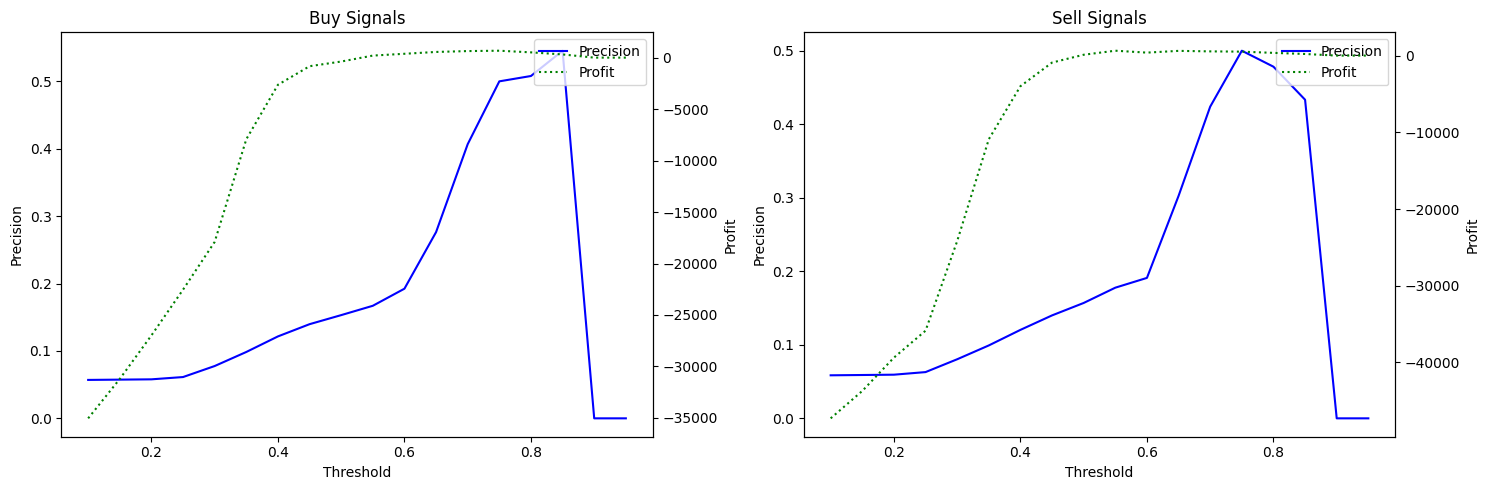


Mejor umbral para compras:
Threshold: 0.75
Profit: 672
Precision: 50.00%

Mejor umbral para ventas:
Threshold: 0.55
Profit: 637
Precision: 17.77%


In [21]:
# Ejemplo de uso
compra_df, venta_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=20,
    pip_stop=5
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")

In [ ]:
import lightgbm as lgb


In [29]:
from sklearn.preprocessing import LabelEncoder
# 1. Preparar los datos
# Codificar la variable objetivo
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)


In [30]:
# Definir parámetros para multiclass classification
params = {
    'objective': 'multiclass',
    'num_class': len(le.classes_),
    'metric': 'multi_logloss',
    'verbosity': -1,
    'seed': 42
}

# Create new datasets with encoded labels
lgb_train = lgb.Dataset(X_train, y_train_encoded)
lgb_test = lgb.Dataset(X_test, y_test_encoded, reference=lgb_train)

# Entrenar el modelo
model = lgb.train(
    params,
    lgb_train,
    valid_sets=[lgb_test]
)

In [31]:
# Predecir
y_pred_proba = model.predict(X_test)  

In [35]:
# Convert probabilities to predictions using argmax
y_pred = le.inverse_transform(y_pred_proba.argmax(axis=1))

# Print classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred))

Classification Report:

                           precision    recall  f1-score   support

    no_objetivo_alcanzado       0.89      1.00      0.94     81581
objetivo_compra_alcanzado       0.64      0.01      0.01      5197
 objetivo_venta_alcanzado       0.59      0.00      0.00      5341

                 accuracy                           0.89     92119
                macro avg       0.70      0.34      0.32     92119
             weighted avg       0.85      0.89      0.83     92119



Buy Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,10.67%,"19,024","-9,682"
1,0.15,16.17%,"1,787",-27
2,0.20,28.74%,247,657
3,0.25,43.65%,126,781
4,0.30,46.60%,103,721
5,0.35,47.83%,92,676
6,0.40,49.35%,77,601
7,0.45,56.25%,64,607
8,0.50,65.12%,43,494
9,0.55,72.73%,22,299



Sell Strategy Metrics:


,threshold,precision,total_trades,profit
0,0.10,10.81%,"18,605","-12,024"
1,0.15,15.51%,"2,225",-322
2,0.20,32.08%,212,721
3,0.25,45.37%,108,730
4,0.30,50.67%,75,611
5,0.35,49.18%,61,481
6,0.40,41.18%,51,306
7,0.45,42.11%,38,246
8,0.50,59.09%,22,224
9,0.55,54.55%,11,95


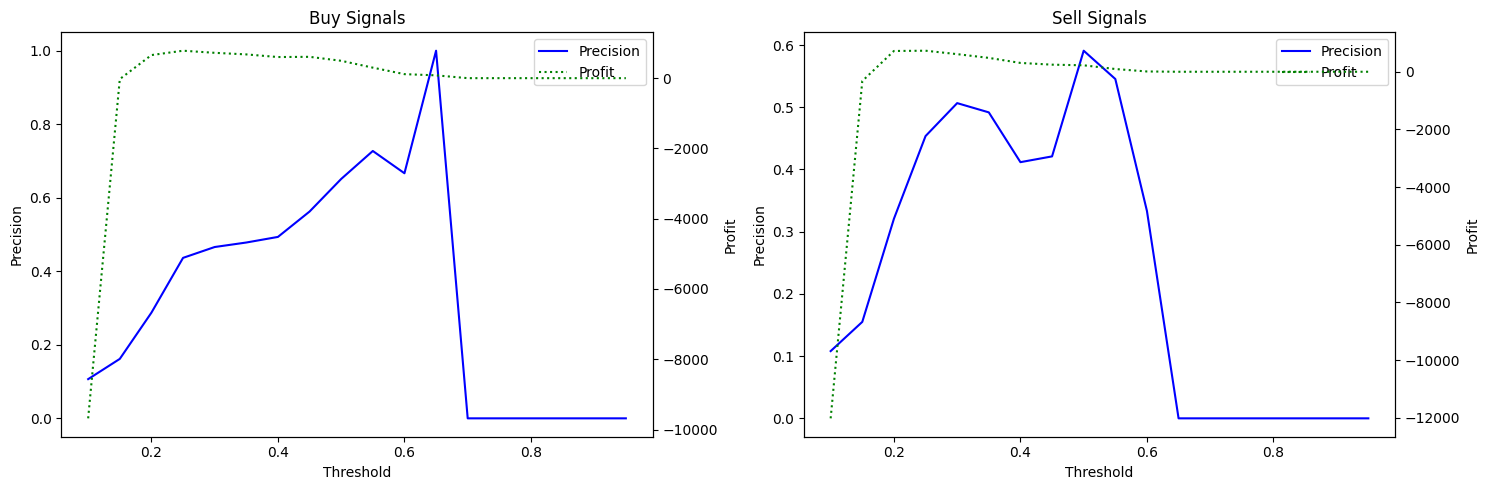


Mejor umbral para compras:
Threshold: 0.25
Profit: 781
Precision: 43.65%

Mejor umbral para ventas:
Threshold: 0.25
Profit: 730
Precision: 45.37%


In [33]:
# Ejemplo de uso
compra_df, venta_df = analizar_metricas_por_umbral(
    y_pred_proba, 
    df_test,
    pip_objetivo=20,
    pip_stop=5
)

# Encontrar el mejor umbral para compras
mejor_umbral_compra = compra_df.loc[compra_df['profit'].idxmax()]
print(f"\nMejor umbral para compras:")
print(f"Threshold: {mejor_umbral_compra['threshold']:.2f}")
print(f"Profit: {mejor_umbral_compra['profit']:.0f}")
print(f"Precision: {mejor_umbral_compra['precision']:.2%}")

# Encontrar el mejor umbral para ventas
mejor_umbral_venta = venta_df.loc[venta_df['profit'].idxmax()]
print(f"\nMejor umbral para ventas:")
print(f"Threshold: {mejor_umbral_venta['threshold']:.2f}")
print(f"Profit: {mejor_umbral_venta['profit']:.0f}")
print(f"Precision: {mejor_umbral_venta['precision']:.2%}")